In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pool_env import PoolEnv
from trainer import TransformerAgent, RewardWrapper

from sb3_contrib.common.maskable.utils import get_action_masks, is_masking_supported
from stable_baselines3.common.vec_env import DummyVecEnv, VecEnv

DEVICE = torch.device("mps" if torch.mps.is_available() else "cpu")
print(DEVICE)


plt.style.use("ggplot")
plt.rcParams["font.family"] = "monospace"
legend_params = {
    "title": "Reward Model",
    "facecolor": "white",
    "edgecolor": "darkgray",
    "frameon": True,
}

ckpt = torch.load(
    # "grpo_pool_final_phase2_1500.pt",
    "checkpoint_phase2_200.pt",
    # "checkpoint_phase2_50.pt",
    weights_only=False,
    map_location=DEVICE,
)

objc[59550]: Class SDLApplication is implemented in both /Users/derekashby/mamba/envs/gym/lib/python3.12/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x14e310890) and /Users/derekashby/mamba/envs/gym/lib/python3.12/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x15094d2c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[59550]: Class SDLAppDelegate is implemented in both /Users/derekashby/mamba/envs/gym/lib/python3.12/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x14e3108e0) and /Users/derekashby/mamba/envs/gym/lib/python3.12/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x15094d318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[59550]: Class SDLTranslatorResponder is implemented in both /Users/derekashby/mamba/envs/gym/lib/python3.12/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x14e310958) and /Users/derekashby/mamba/envs/gy

pygame 2.6.1 (SDL 2.28.4, Python 3.12.13)
Hello from the pygame community. https://www.pygame.org/contribute.html
mps


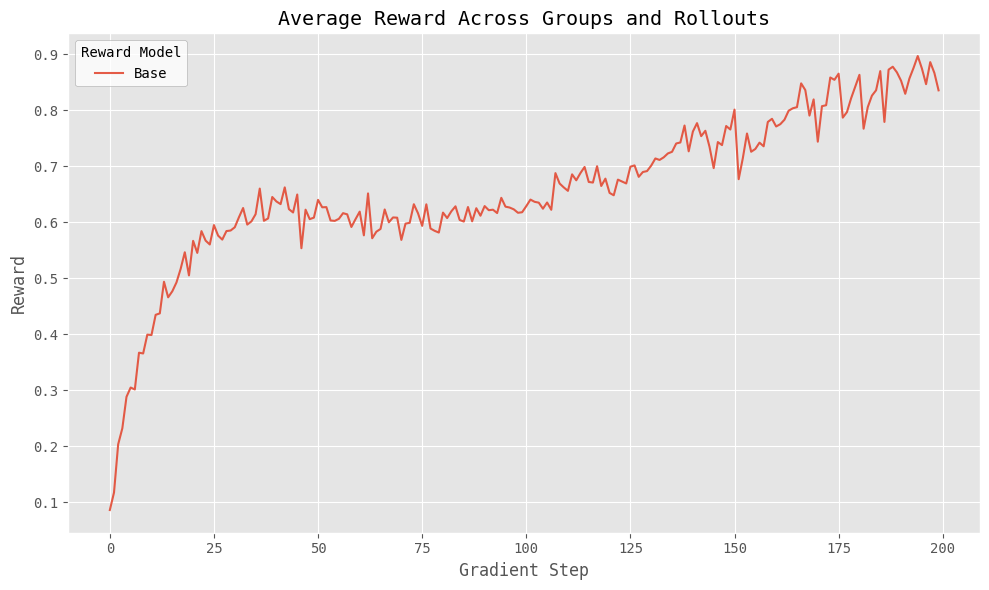

In [2]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    ckpt["rewards"].mean(axis=2).mean(axis=1)[:200],
    label="Base",
    alpha=0.9,
)

plt.title("Average Reward Across Groups and Rollouts")
plt.xlabel("Gradient Step")
plt.ylabel("Reward")
plt.legend(**legend_params)

handles, labels = plt.gca().get_legend_handles_labels()

plt.tight_layout()
plt.show()

In [3]:
ckpt["rewards"][199].mean(axis=0).mean(axis=0)

np.float64(0.835748871082567)

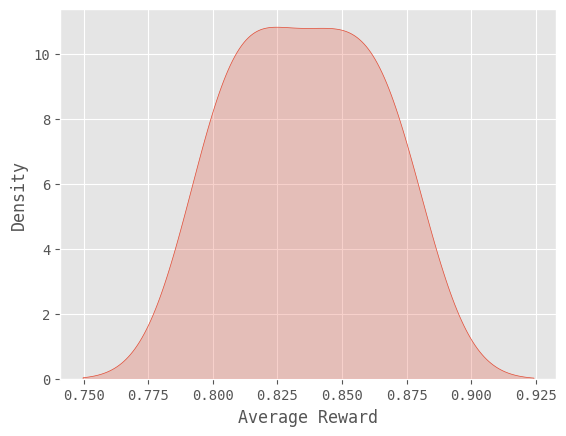

In [4]:
# Distribution of average reward across groups
sns.kdeplot(ckpt["rewards"][199].mean(axis=1), fill=True)
plt.xlabel("Average Reward")
plt.show()

In [5]:
def run_model(
    model, env_test, max_steps, render=True, deterministic=True, use_masking=False
):
    if use_masking and not is_masking_supported(env_test):
        raise ValueError(
            "Environment does not support action masking. Consider using ActionMasker wrapper"
        )

    if not isinstance(env_test, VecEnv):
        env_test = DummyVecEnv([lambda: env_test])

    steps = 0
    success_rate = []
    success_rate_one_ball = []
    rew = []
    first_step = True
    obs = env_test.reset()

    while steps < max_steps:
        obs = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)
        _, action, _ = model.get_action(obs)

        action = action.cpu().numpy()
        obs, rewards, dones, info = env_test.step(action)
        if render:
            env_test.render()

        if first_step:
            balls_pocketed = [b.ballclass for b in info[0].get("ball_pocketed")]
            # print(balls_pocketed)
            success_rate_one_ball.append(True if 2 in balls_pocketed else False)
            first_step = False

        if dones[0]:
            if steps % int(max_steps / 20) == 0:
                print(f"{(steps / max_steps) * 100}%")
            steps += 1
            success_rate.append(info[0].get("is_success"))

            rew.append(rewards[0])
            first_step = True
            obs = env_test.reset()

    success_rate = np.mean(success_rate)
    success_rate_one_ball = np.mean(success_rate_one_ball)
    rew_mean = np.mean(rew)
    rew_std = np.std(rew)
    return (success_rate, success_rate_one_ball, rew_mean, rew_std)

In [ ]:
env = RewardWrapper(
    PoolEnv(
        algo="GRPO",
        obs_type="vector",
        training=False,
        num_balls=2,
        game_type="normal",
        fps=30,
        curriculum_phase=1,
    )
)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]

policy = TransformerAgent(state_dim, n_head=4, n_layers=2).to(DEVICE)
policy.load_state_dict(ckpt["model_state_dict"])

while True:
    try:
        run_model(policy, env, max_steps=1, render=True, use_masking=False)
    except Exception:
        pass


[Phase 1 Init] Target: (735.0, 697.0) | Cue: (746.5, 642.2) | Pocket: (735.0, 725.0)


KeyboardInterrupt: 

: 